# Willamette: verifica della regola di stabilità a un’ora

## Risultato in breve
La regola riduce l’errore della regressione completa, ma **non supera l’ultima misura invariata**. La decisione predefinita è `no-overall-improvement`: non promuoviamo il modello operativo.

La MAE media delle quattro stagioni è circa **0,08902 mg/L** per la persistenza, **0,09355 mg/L** per il ridge completo e **0,09247 mg/L** per il ridge con regola. La regola migliora il ridge di circa **1,16%**, ma peggiora la persistenza di circa **3,87%**. Le celle successive ricalcolano questi numeri dagli archivi e ne verificano l’accordo con la valutazione salvata.

Questa è una verifica **retrospettiva**, su una stazione e quattro periodi storici scelti prima della nuova acquisizione. Non è una previsione emessa in tempo reale né una validazione sul campo.

## Contesto e metodo
**Domanda:** se dodici misure passate di ossigeno, distanziate di trenta minuti, sono esattamente uguali, conviene annullare la correzione del ridge?

Qui il modello è una **regressione numerica**, non un LLM. Manteniamo gli otto ingressi, le medie, le scale, i coefficienti e l’intercetta già congelati. Non facciamo fit, ricerca di parametri o nuove richieste HTTP.

La regola usa soltanto la storia dall’origine meno cinque ore e trenta minuti fino all’origine. Se tutti i dodici valori pubblicati sono identici, prevede l’ultima misura; altrimenti usa il ridge completo. “Identici” riguarda i valori pubblicati, non la stabilità fisica dell’ecosistema.

### Assunzioni e criteri fissati
Gli stessi casi validi devono essere disponibili per tutti e tre i metodi. Le quattro MAE stagionali hanno **uguale peso**. Dati mancanti, perdite stagionali e grandi errori non vengono eliminati per rendere favorevole il risultato. Il 10% non è una soglia di accettazione. Gli intervalli bootstrap sono esplorativi e condizionati alle finestre scelte.

### 1. Preparare l’ambiente
Servono Python, `nbformat`, `nbclient`, `ipykernel` e `matplotlib`. Eseguire tutte le celle in ordine, dalla radice della repository o dalla cartella del notebook. Non servono credenziali, un LLM o accesso alle fonti online; servono gli archivi e la storia Git locale del commit congelato.

In [1]:
from pathlib import Path
from datetime import datetime
import sys, json, gzip, hashlib, math, statistics, importlib.metadata
import socket
from IPython.display import display, Markdown

repo = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p/'scripts/evaluate_stability.py').is_file()
             and (p/'docs/datasets/usgs-willamette-stability/protocol.json').is_file()), None)
assert repo is not None, 'Eseguire dalla repository con gli archivi conservati.'
sys.path.insert(0, str(repo/'scripts'))
import evaluate_stability as frozen_evaluator

# Questo processo di lettura e replay non deve aprire connessioni di rete.
def offline_connection(*args, **kwargs):
    raise RuntimeError('Notebook offline: connessione di rete non consentita.')
socket.create_connection = offline_connection

report_path = repo/'docs/evidence/willamette-stability/evaluation.json.gz'
protocol_path = repo/'docs/datasets/usgs-willamette-stability/protocol.json'
model_path = repo/'docs/evidence/willamette-multiseason/frozen-model.json'
report = frozen_evaluator.read_report(report_path)
protocol = json.loads(protocol_path.read_bytes())
sha256 = lambda p: '0x' + hashlib.sha256(p.read_bytes()).hexdigest()
assert sha256(protocol_path) == report['protocolHash']
assert sha256(model_path) == report['frozenModelHash'] == protocol['baseModel']['rawSha256']
assert report['stationId'] == protocol['stationId'] == 'USGS-14211720'
assert report['horizonSeconds'] == protocol['horizonSeconds'] == 3600
assert report['modelRefittedDuringEvaluation'] is False
assert report['operationalModelChanged'] is False
methods = report['methods']
labels = {'persistence':'Ultima misura',
          'same-frozen-ridge-without-fallback':'Ridge completo',
          'same-frozen-ridge-with-fallback':'Ridge + regola'}
season_labels = {'winter':'Inverno','spring':'Primavera','summer':'Estate','autumn':'Autunno'}
versions = {name: importlib.metadata.version(name) for name in ['nbformat','nbclient','ipykernel','matplotlib']}
print(json.dumps({'versioni':versions, 'sha256_report_compresso':sha256(report_path),
                  'sha256_protocollo':report['protocolHash'], 'sha256_pesi':report['frozenModelHash']}, indent=2))

{
  "versioni": {
    "nbformat": "5.11.1",
    "nbclient": "0.11.0",
    "ipykernel": "7.4.0",
    "matplotlib": "3.11.2"
  },
  "sha256_report_compresso": "0x5295b0a92a3f6d7c6dbec2efce5cbe1f407cbc5307fa992c4b48d479f020545f",
  "sha256_protocollo": "0xdb27fb083dc830b977268cd0572ab2c451cb3e12f833e7016fb4b6dff665d522",
  "sha256_pesi": "0x72d7d14221c7b14c173dba59d69d2a1d36cbb27ee146378b9e046eea998762c9"
}


### 2. Riprodurre la valutazione congelata
Il replay richiama lo stesso programma congelato: ricontrolla archivi e impegni Git, ricostruisce le previsioni e ripete anche i bootstrap fissati. **È una verifica di riproducibilità, non un audit scientifico indipendente.** Non modifica né riscrive il report salvato.

In [2]:
replayed = frozen_evaluator.evaluate(repo)
maximum_difference = frozen_evaluator.shared.compare_saved(replayed, report, 'notebook stability replay')
assert replayed['decision'] == report['decision'] == 'no-overall-improvement'
print(json.dumps({'replay_verificato':True, 'differenza_massima':maximum_difference,
                  'decisione':report['decision'], 'nuovo_fit':False, 'nuova_acquisizione':False}, indent=2))

{
  "replay_verificato": true,
  "differenza_massima": 0.0,
  "decisione": "no-overall-improvement",
  "nuovo_fit": false,
  "nuova_acquisizione": false
}


## Dati
### 3. Leggere calendario, copertura e assenze
Ogni finestra ha 1.332 origini teoriche. Sono richieste almeno 1.000 coppie e almeno il 90% di copertura: i due criteri valgono insieme. Gli orari assenti restano nel denominatore. Le esclusioni non vengono interpolate o rimpiazzate con zeri.

In [3]:
def show_table(headers, rows):
    def cell(value):
        if value is None: return '—'
        return str(value).replace('|','&#124;').replace('\n',' ')
    text = '| ' + ' | '.join(headers) + ' |\n|' + '|'.join(['---']*len(headers)) + '|\n'
    text += '\n'.join('| ' + ' | '.join(cell(v) for v in row) + ' |' for row in rows)
    display(Markdown(text))

quality_rows=[]
for w in report['windows']:
    grid=w['fullExpectedGrid']; window=w['window']
    assert window in protocol['testWindows']
    assert w['captureCommitment']['frozenAtCommit'] == 'e8b4e133aa81ecda548480991584239a8ed142ea'
    assert w['captureCommitment']['verifiedAgainstCurrentFilesAndGit'] is True
    assert grid['acceptedExactGridPairs'] == len(w['rows'])
    assert grid['acceptedExactGridPairs'] + grid['missingApprovedOxygenOrigins'] + grid['presentOriginsWithIncompleteHistoryOrTarget'] == grid['expectedOrigins']
    assert math.isclose(grid['acceptedGridFraction'], len(w['rows'])/grid['expectedOrigins'], abs_tol=1e-15)
    quality_rows.append([season_labels[window['season']],window['start'][:10],window['end'][:10],
                         grid['expectedOrigins'],len(w['rows']),f"{100*grid['acceptedGridFraction']:.2f}%",
                         grid['missingApprovedOxygenOrigins'],grid['presentOriginsWithIncompleteHistoryOrTarget'],w['dataScreenPassed']])
show_table(['Stagione','Inizio UTC','Fine UTC','Origini attese','Coppie','Copertura','Origini O₂ assenti','Storia/target incompleti','Filtro superato'],quality_rows)
print('Totale coppie:',sum(len(w['rows']) for w in report['windows']))

| Stagione | Inizio UTC | Fine UTC | Origini attese | Coppie | Copertura | Origini O₂ assenti | Storia/target incompleti | Filtro superato |
|---|---|---|---|---|---|---|---|---|
| Inverno | 2025-02-01 | 2025-03-01 | 1332 | 1276 | 95.80% | 17 | 39 | True |
| Primavera | 2025-05-01 | 2025-05-29 | 1332 | 1320 | 99.10% | 0 | 12 | True |
| Estate | 2025-06-01 | 2025-06-29 | 1332 | 1298 | 97.45% | 8 | 26 | True |
| Autunno | 2025-11-01 | 2025-11-29 | 1332 | 1319 | 99.02% | 1 | 12 | True |

Totale coppie: 5213


### 4. Ispezionare un campione deterministico
Le prime dieci righe della prima finestra mostrano origine, target, misura osservata e le tre previsioni. Il flag di storia invariata dipende solo dalle dodici misure precedenti. Il target entra nel calcolo dell’errore dopo la previsione.

In [4]:
sample=report['windows'][0]['rows'][:10]
show_table(['Origine UTC','Target UTC','O₂ osservato','Ultima misura','Ridge completo','Ridge + regola','Storia invariata'],
 [[r['origin'],r['target'],f"{r['actual']:.4f}",*[f"{r['predictionsMgL'][m]:.4f}"for m in methods],r['historyFlat']] for r in sample])
for w in report['windows']:
    for r in w['rows']:
        history=r['oxygenHistory']; values=[h['value'] for h in history]
        instant=lambda s:datetime.fromisoformat(s.replace('Z','+00:00'))
        assert len(history)==12 and history[-1]['timeUTC']==r['origin']
        assert all((instant(history[i+1]['timeUTC'])-instant(history[i]['timeUTC'])).total_seconds()==1800 for i in range(11))
        assert (instant(r['target'])-instant(r['origin'])).total_seconds()==3600
        assert r['historyFlat']==all(value==values[0]for value in values)
        assert r['residualMultiplier']==(0 if r['historyFlat']else 1)
        expected=r['predictionsMgL']['persistence'] if r['historyFlat'] else r['predictionsMgL']['same-frozen-ridge-without-fallback']
        assert r['predictionsMgL']['same-frozen-ridge-with-fallback']==expected
print('Allineamento temporale e applicazione della regola verificati su tutte le righe.')

| Origine UTC | Target UTC | O₂ osservato | Ultima misura | Ridge completo | Ridge + regola | Storia invariata |
|---|---|---|---|---|---|---|
| 2025-02-01T05:30:00.000Z | 2025-02-01T06:30:00.000Z | 13.7000 | 13.8000 | 13.7879 | 13.8000 | True |
| 2025-02-01T06:00:00.000Z | 2025-02-01T07:00:00.000Z | 13.7000 | 13.7000 | 13.7327 | 13.7327 | False |
| 2025-02-01T06:30:00.000Z | 2025-02-01T07:30:00.000Z | 13.7000 | 13.7000 | 13.7113 | 13.7113 | False |
| 2025-02-01T07:00:00.000Z | 2025-02-01T08:00:00.000Z | 13.7000 | 13.7000 | 13.7119 | 13.7119 | False |
| 2025-02-01T07:30:00.000Z | 2025-02-01T08:30:00.000Z | 13.7000 | 13.7000 | 13.7106 | 13.7106 | False |
| 2025-02-01T08:00:00.000Z | 2025-02-01T09:00:00.000Z | 13.6000 | 13.7000 | 13.6913 | 13.6913 | False |
| 2025-02-01T08:30:00.000Z | 2025-02-01T09:30:00.000Z | 13.6000 | 13.7000 | 13.6928 | 13.6928 | False |
| 2025-02-01T09:00:00.000Z | 2025-02-01T10:00:00.000Z | 13.6000 | 13.6000 | 13.6392 | 13.6392 | False |
| 2025-02-01T09:30:00.000Z | 2025-02-01T10:30:00.000Z | 13.6000 | 13.6000 | 13.6196 | 13.6196 | False |
| 2025-02-01T10:00:00.000Z | 2025-02-01T11:00:00.000Z | 13.6000 | 13.6000 | 13.6217 | 13.6217 | False |

Allineamento temporale e applicazione della regola verificati su tutte le righe.


## Risultati
### 5. Ricalcolare gli errori senza cambiare il modello
La **MAE** è la media degli errori assoluti; la **RMSE** pesa maggiormente gli errori grandi; il **bias** è la media di previsione meno osservazione. Il p95 indica il percentile 95 dell’errore assoluto, con interpolazione lineare. Tutti sono espressi in mg/L. Calcoliamo questi valori direttamente dalle righe salvate, poi li confrontiamo con il report.

In [5]:
def percentile(values,q):
    ordered=sorted(values);position=(len(ordered)-1)*q
    low=math.floor(position);high=math.ceil(position)
    return ordered[low]+(ordered[high]-ordered[low])*(position-low)

def row_scores(rows,method):
    errors=[r['predictionsMgL'][method]-r['actual']for r in rows]
    return {'pairs':len(errors),'maeMgL':sum(abs(e)for e in errors)/len(errors),
            'rmseMgL':math.sqrt(sum(e*e for e in errors)/len(errors)),
            'biasMgL':sum(errors)/len(errors),'p95AbsoluteErrorMgL':percentile([abs(e)for e in errors],.95)}

metric_rows=[]
for w in report['windows']:
    for method in methods:
        actual=row_scores(w['rows'],method);saved=w['scores'][method]
        for key,value in actual.items():assert math.isclose(value,saved[key],rel_tol=1e-12,abs_tol=1e-12),(w['window']['id'],method,key)
        metric_rows.append([season_labels[w['window']['season']],labels[method],actual['pairs'],*[f"{actual[k]:.8f}"for k in ['maeMgL','rmseMgL','biasMgL','p95AbsoluteErrorMgL']]])
show_table(['Stagione','Metodo','Coppie','MAE mg/L','RMSE mg/L','Bias mg/L','p95 errore mg/L'],metric_rows)
macro={m:sum(w['scores'][m]['maeMgL']for w in report['windows'])/4 for m in methods}
for m in methods:assert math.isclose(macro[m],report['macro']['seasonalMeanMAEMgL'][m],abs_tol=1e-15)
show_table(['Metodo','MAE media delle quattro stagioni mg/L'],[[labels[m],f'{macro[m]:.11f}']for m in methods])

| Stagione | Metodo | Coppie | MAE mg/L | RMSE mg/L | Bias mg/L | p95 errore mg/L |
|---|---|---|---|---|---|---|
| Inverno | Ultima misura | 1276 | 0.01708464 | 0.04133357 | 0.00047022 | 0.10000000 |
| Inverno | Ridge completo | 1276 | 0.02846861 | 0.04159907 | 0.00668629 | 0.09937248 |
| Inverno | Ridge + regola | 1276 | 0.02458599 | 0.04048175 | 0.00493217 | 0.10000000 |
| Primavera | Ultima misura | 1320 | 0.08333333 | 0.14984841 | 0.00090909 | 0.30000000 |
| Primavera | Ridge completo | 1320 | 0.08981269 | 0.13977841 | 0.00301002 | 0.29570620 |
| Primavera | Ridge + regola | 1320 | 0.08972269 | 0.13986492 | 0.00268059 | 0.29570620 |
| Estate | Ultima misura | 1298 | 0.20169492 | 0.33896880 | -0.00277350 | 0.80000000 |
| Estate | Ridge completo | 1298 | 0.19359997 | 0.30306536 | -0.00355101 | 0.67260426 |
| Estate | Ridge + regola | 1298 | 0.19359997 | 0.30306536 | -0.00355101 | 0.67260426 |
| Autunno | Ultima misura | 1319 | 0.05398029 | 0.08964592 | -0.00015163 | 0.20000000 |
| Autunno | Ridge completo | 1319 | 0.06233747 | 0.08596532 | 0.00557404 | 0.19138725 |
| Autunno | Ridge + regola | 1319 | 0.06197262 | 0.08585762 | 0.00552349 | 0.19175616 |

| Metodo | MAE media delle quattro stagioni mg/L |
|---|---|
| Ultima misura | 0.08902329405 |
| Ridge completo | 0.09355468323 |
| Ridge + regola | 0.09247031806 |

### 6. Confrontare le quattro stagioni
Il grafico parte da zero e mantiene distinti i tre metodi. Un errore più basso è migliore. Le differenze stagionali contano: il solo confronto con il ridge completo non basta a stabilire che serva un modello più complesso della persistenza.

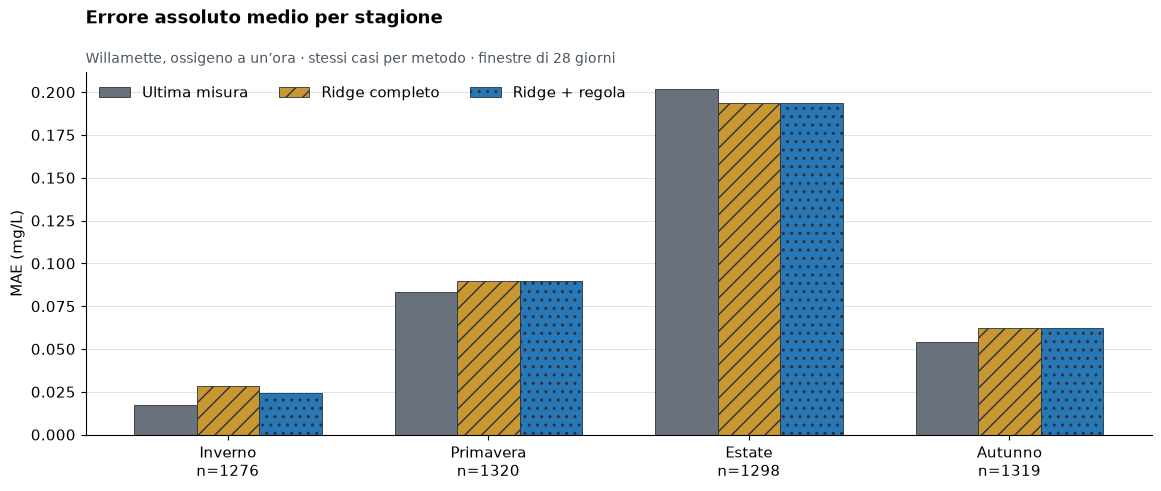

In [6]:
from IPython import get_ipython
get_ipython().run_line_magic('matplotlib','inline')
import matplotlib.pyplot as plt
colors=['#69727C','#C99732','#2878B5'];hatches=['','//','..']
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.spines.top':False,'axes.spines.right':False,'axes.axisbelow':True})
fig,ax=plt.subplots(figsize=(11.5,4.8),layout='constrained')
width=.24
for j,m in enumerate(methods):
    ax.bar([i+(j-1)*width for i in range(4)],[w['scores'][m]['maeMgL']for w in report['windows']],width=width,
           color=colors[j],edgecolor='#29313A',linewidth=.6,hatch=hatches[j],label=labels[m])
ax.set_xticks(range(4),[season_labels[w['window']['season']]+'\nn='+str(len(w['rows']))for w in report['windows']])
ax.set_ylim(bottom=0);ax.set_ylabel('MAE (mg/L)');ax.grid(axis='y',color='#D9DDE1',linewidth=.6)
ax.set_title('Errore assoluto medio per stagione',loc='left',fontweight='bold',pad=35)
ax.text(0,1.025,'Willamette, ossigeno a un’ora · stessi casi per metodo · finestre di 28 giorni',transform=ax.transAxes,fontsize=10,color='#4B5563')
ax.legend(loc='upper left',frameon=False,ncol=3);plt.show()

### 7. Distinguere i due confronti
Il vantaggio è **MAE del confronto − MAE della regola**: positivo significa che la regola fa meglio. Il valore negativo rispetto alla persistenza significa invece un peggioramento. Le percentuali hanno denominatori diversi: non vanno confuse.

In [7]:
gain_rows=[]
for baseline,gain in report['macro']['gainAgainstBaselines'].items():
    computed=macro[baseline]-macro['same-frozen-ridge-with-fallback']
    assert math.isclose(computed,gain['gainMgL'],abs_tol=1e-15)
    gain_rows.append([labels[baseline],f"{gain['gainMgL']:+.11f}",f"{gain['relativeGainPercent']:+.6f}%"])
show_table(['Confronto','Vantaggio della regola mg/L','Vantaggio relativo'],gain_rows)
assert macro['same-frozen-ridge-with-fallback']>macro['persistence']
assert macro['same-frozen-ridge-with-fallback']<macro['same-frozen-ridge-without-fallback']
display(Markdown('**La regola corregge una parte del problema del ridge, ma non supera la persistenza.** Questo è il motivo centrale del mancato miglioramento complessivo.'))

| Confronto | Vantaggio della regola mg/L | Vantaggio relativo |
|---|---|---|
| Ultima misura | -0.00344702402 | -3.872047% |
| Ridge completo | +0.00108436517 | +1.159071% |

**La regola corregge una parte del problema del ridge, ma non supera la persistenza.** Questo è il motivo centrale del mancato miglioramento complessivo.

### 8. Contare quando interviene la regola
Questi gruppi dipendono dalla storia passata, non dal target futuro. Nel gruppo invariato, la regola coincide con la persistenza per costruzione. Se un gruppo fosse vuoto, la sua metrica sarebbe assente, non zero. Anche un gruppo numeroso non dimostra da solo la stabilità fisica dell’ecosistema.

In [8]:
flat_rows=[]
for w in report['windows']:
    group=w['subgroups']['past-flat'];n=group['pairs']
    assert n==sum(r['historyFlat']for r in w['rows'])
    score=group['scores']
    flat_rows.append([season_labels[w['window']['season']],n,f"{100*n/len(w['rows']):.2f}%",*[f"{score[m]['maeMgL']:.8f}"if n else None for m in methods]])
show_table(['Stagione','Storie invariate','Quota dei casi','MAE persistenza','MAE ridge','MAE regola'],flat_rows)

| Stagione | Storie invariate | Quota dei casi | MAE persistenza | MAE ridge | MAE regola |
|---|---|---|---|---|---|
| Inverno | 439 | 34.40% | 0.01343964 | 0.02472487 | 0.01343964 |
| Primavera | 42 | 3.18% | 0.06666667 | 0.06949527 | 0.06666667 |
| Estate | 0 | 0.00% | — | — | — |
| Autunno | 52 | 3.94% | 0.04615385 | 0.05540827 | 0.04615385 |

### 9. Leggere l’incertezza senza trattare le righe come indipendenti
Il bootstrap ricampiona gli stessi blocchi temporali per tutti e tre i metodi, dentro ciascuna stagione. Ogni ricampionamento mantiene uguale il peso delle stagioni. Il blocco principale è di 48 ore; 24 e 72 ore sono sensibilità, non nuove conferme indipendenti. Gli intervalli non sono intervalli di previsione del prossimo valore del fiume.

| Blocco ore | Confronto | Ricampionamenti | Seme | Limite inferiore mg/L | Limite superiore mg/L |
|---|---|---|---|---|---|
| 48 | Ultima misura | 5000 | 20261062 | -0.00543163432 | -0.00166675947 |
| 48 | Ridge completo | 5000 | 20261062 | +0.00078516602 | +0.00137458439 |
| 24 | Ultima misura | 5000 | 20261038 | -0.00500775403 | -0.00194279103 |
| 24 | Ridge completo | 5000 | 20261038 | +0.00077925402 | +0.00142457985 |
| 72 | Ultima misura | 5000 | 20261086 | -0.00519142699 | -0.00172182389 |
| 72 | Ridge completo | 5000 | 20261086 | +0.00076509615 | +0.00139021062 |

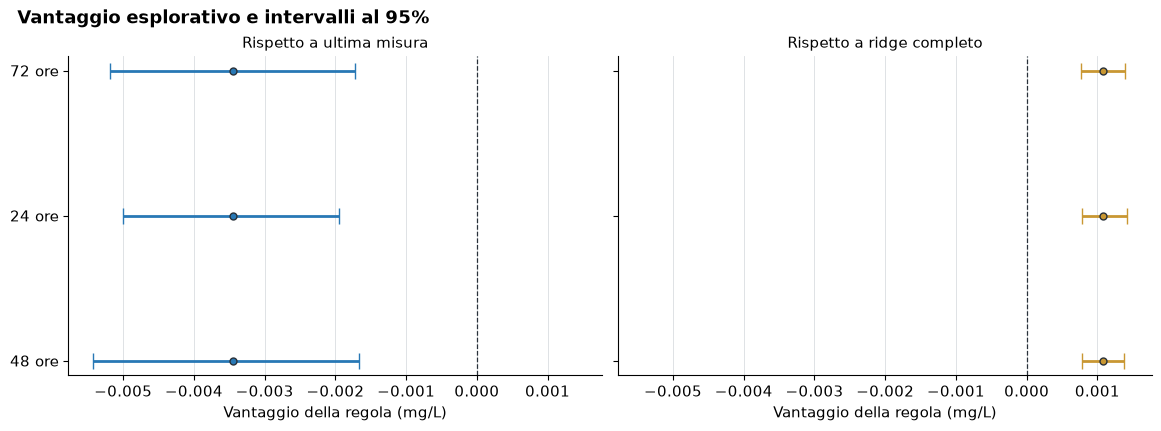

In [9]:
band_rows=[]
for band in report['bootstrap']:
    for baseline,interval in band['gainAgainstBaselines'].items():
        band_rows.append([band['blockHours'],labels[baseline],band['iterations'],band['seed'],
                          f"{interval['lowerGainMgL']:+.11f}",f"{interval['upperGainMgL']:+.11f}"])
show_table(['Blocco ore','Confronto','Ricampionamenti','Seme','Limite inferiore mg/L','Limite superiore mg/L'],band_rows)
fig,axes=plt.subplots(1,2,figsize=(11.5,4.2),sharex=True,sharey=True,layout='constrained')
for ax,baseline,color in zip(axes,['persistence','same-frozen-ridge-without-fallback'],['#2878B5','#C99732']):
    for y,band in enumerate(report['bootstrap']):
        limits=band['gainAgainstBaselines'][baseline];lo=limits['lowerGainMgL'];hi=limits['upperGainMgL'];point=report['macro']['gainAgainstBaselines'][baseline]['gainMgL']
        ax.hlines(y,lo,hi,color=color,linewidth=2);ax.plot([lo,hi],[y,y],'|',color=color,markersize=11);ax.plot(point,y,'o',color=color,markeredgecolor='#29313A',markersize=5)
    ax.axvline(0,color='#29313A',linewidth=.9,linestyle='--');ax.set_title('Rispetto a '+labels[baseline].lower(),fontsize=11);ax.grid(axis='x',color='#D9DDE1',linewidth=.6)
    ax.set_yticks(range(3),[str(b['blockHours'])+' ore'for b in report['bootstrap']]);ax.set_xlabel('Vantaggio della regola (mg/L)')
fig.suptitle('Vantaggio esplorativo e intervalli al 95%',fontweight='bold',ha='left',x=.01)
plt.show()

## Limiti e verifiche della decisione
### 10. Applicare i criteri dichiarati prima dei risultati
Non cambiamo la soglia dopo aver visto l’esito. La validità delle previsioni, la completezza dei dati e una correzione del ridge non equivalgono a battere la baseline. Manteniamo anche i controlli falliti, invece di fermarci a un miglioramento favorevole.

In [10]:
fallback='same-frozen-ridge-with-fallback';baselines=['persistence','same-frozen-ridge-without-fallback'];tol=protocol['decision']['numericalToleranceMgL']
checks={
 'Tutte le finestre superano la completezza':all(w['dataScreenPassed']for w in report['windows']),
 'Esistono casi con storia invariata':any(w['subgroups']['past-flat']['pairs']for w in report['windows']),
 'MAE media migliore di entrambi i confronti':all(report['macro']['gainAgainstBaselines'][b]['gainMgL']>tol for b in baselines),
 'Nessuna perdita MAE stagionale contro entrambi':all(w['scores'][fallback]['maeMgL']<=w['scores'][b]['maeMgL']+tol for w in report['windows']for b in baselines),
 'Limiti inferiori positivi in tutti i bootstrap':all(band['gainAgainstBaselines'][b]['lowerGainMgL']>tol for band in report['bootstrap']for b in baselines),
 'Previsioni finite e regola non negativa':all(all(v==0 for v in w['predictionDiagnostics']['nonfinitePredictions'].values())and w['predictionDiagnostics']['negativePredictions'][fallback]==0 for w in report['windows'])}
show_table(['Criterio congelato','Superato'],list(checks.items()))
print('Decisione archiviata:',report['decision'])
show_table(['Stagione','Target sotto 5 mg/L (solo descrizione)','Casi con ingressi fuori range di training'],[[season_labels[w['window']['season']],w['approvedTargetsBelowIllustrative5MgL']['pairs'],w['featureExtrapolation']['pairs']]for w in report['windows']])

| Criterio congelato | Superato |
|---|---|
| Tutte le finestre superano la completezza | True |
| Esistono casi con storia invariata | True |
| MAE media migliore di entrambi i confronti | False |
| Nessuna perdita MAE stagionale contro entrambi | False |
| Limiti inferiori positivi in tutti i bootstrap | False |
| Previsioni finite e regola non negativa | True |

Decisione archiviata: no-overall-improvement


| Stagione | Target sotto 5 mg/L (solo descrizione) | Casi con ingressi fuori range di training |
|---|---|---|
| Inverno | 0 | 376 |
| Primavera | 0 | 2 |
| Estate | 0 | 94 |
| Autunno | 0 | 0 |

## Che cosa abbiamo imparato e che cosa resta aperto
La regola **migliora il ridge ma non giustifica il suo impiego al posto della persistenza** su queste finestre. Rimaniamo a un’ora e conserviamo questo risultato negativo; un cambiamento di variabili, pesi o regole richiederà un altro protocollo e dati separati.

Le misure sono valori storici finalizzati: non dimostrano che fossero disponibili, con lo stesso contenuto, all’istante originario. Quattro finestre di una stazione non rappresentano tutto il bacino o tutti gli anni. I controlli di hash e Git rendono il replay controllabile rispetto agli archivi salvati; non provano da soli la verità fisica delle misure o un timestamp esterno indipendente.

La soglia descrittiva di 5 mg/L non è una soglia ecologica locale validata. Il controllo dei range delle singole variabili non è un dominio di applicabilità validato. Il bootstrap non certifica un’utilità ambientale.

La missione di Virdacora resta fornire prove ambientali verificabili a sostegno dei diritti decisionali delle comunità e dei giovani. Questo notebook non cambia Oracle operativo, governance, quorum, tesoreria, token o spese, e non dimostra attribuzione degli inquinanti, efficacia di interventi o benefici sul campo.

**Prossimo passo da discutere:** capire perché il ridge resta peggiore della baseline nelle stagioni problematiche, prima di ampliare l’orizzonte o addestrare un nuovo modello.